# The S&P 500 next week: the direction and the size are different questions

**None of the forecasters here calls next week's direction better than always saying "up". The size of the move is another matter: a 90% range built from the last half year held in calm years and in crashes, while one built from all of history held on 60% of the weeks of 2008.**

Most people who look at a share index want to know where it is going. Sixty-six years of weekly changes say that question has no answer here. A second question does have one: how big will the move be? Someone holding an index fund cannot use the first answer, because there isn't one. Anyone deciding how much to hold, or how large a fall to be ready for, can use the second. This notebook asks both questions in the same way, on the same weeks.

*Data: the S&P 500 index at the end of each week, 1950 to 2015, from the R package gt ([source and license](data/README.md#share-index)). The index leaves out dividends, and a fund that tracks it also charges fees. To run this notebook yourself, see [Run an example yourself](../docs/examples.md#run-an-example-yourself).*

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LinearRegression

from timegym import Forecast, Pipeline, cases_from_series
from timegym.statistics import paired_t_interval

from example_data import load  # examples/example_data.py, next to this notebook

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## The job

Each Friday, say something useful about the index's change over the coming week. The table has the closing level at the end of each week; we work with the change from one week to the next, in percent.

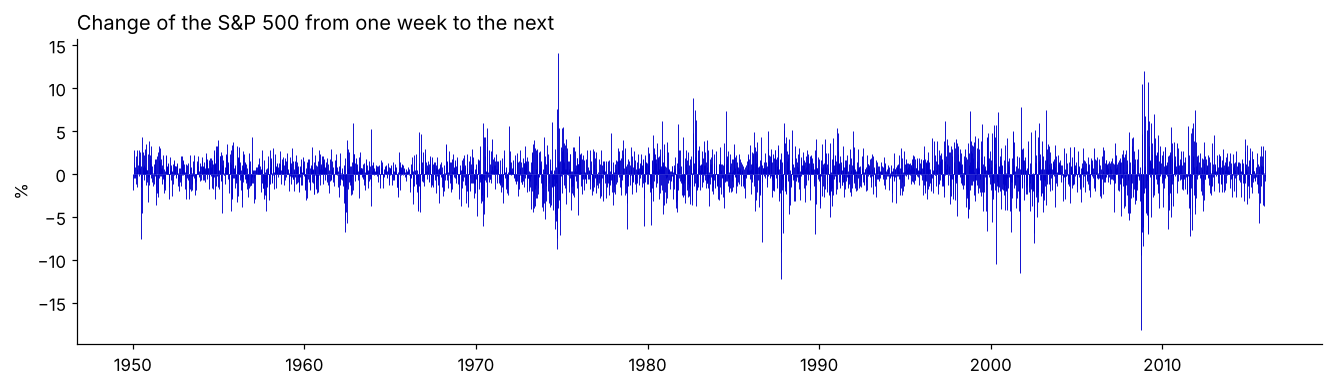

3,443 weeks, 13 January 1950 to 01 January 2016.
Average change: +0.16% a week. Average size of a change: 1.52%.
Weeks that ended higher: 56.5%.
Largest fall: -18.2% (week to 10 October 2008).
Largest rise: +14.1% (week to 11 October 1974).


In [2]:
close = load("sp500")["close"]
changes = (100 * close.pct_change()).dropna().to_frame("change")
changes.index.freq = close.index.freq

fig, ax = plt.subplots(figsize=(12, 3.4), layout="constrained")
ax.vlines(changes.index, 0, changes["change"], color="#0000CC", linewidth=0.6)
ax.set(title="Change of the S&P 500 from one week to the next", ylabel="%")
plt.show()

week = changes["change"]
print(f"{len(week):,} weeks, {week.index[0]:%d %B %Y} to {week.index[-1]:%d %B %Y}.")
print(f"Average change: {week.mean():+.2f}% a week. Average size of a change: {week.abs().mean():.2f}%.")
print(f"Weeks that ended higher: {100 * (week > 0).mean():.1f}%.")
print(f"Largest fall: {week.min():.1f}% (week to {week.idxmin():%d %B %Y}).")
print(f"Largest rise: {week.max():+.1f}% (week to {week.idxmax():%d %B %Y}).")
assert len(week) == 3443 and round(100 * (week > 0).mean(), 1) == 56.5

The index rises in a little over half of all weeks, by a tenth or two of a percent on average, and a typical week moves it ten times that far in one direction or the other. The picture also shows something the averages hide: the big weeks come in clusters.

## Which way?

Four forecasters give a number for next week's change. Each one sees only the weeks before the Friday it forecasts from.

- **Average of history** is the average weekly change so far, which is always a small plus. As a call on the direction it is "always up".
- **Same as last week** expects the last change to repeat.
- **Average of the last 13 weeks** follows the recent quarter.
- **Regression on the last 4 weeks** is a linear regression, refit each Friday.

Every Friday from 1970 on is a test case, so each forecast has at least 20 years behind it. Beside the average miss we record a metric of our own: was the direction right?

In [3]:
class Average:
    "The average of the last so many weeks, or of all history."

    def __init__(self, weeks=None):
        self.weeks = weeks

    def fit(self, history):
        values = np.asarray(history, dtype=float).ravel()
        self.level_ = float(values[-self.weeks:].mean() if self.weeks else values.mean())
        return self

    def predict(self, dates):
        return np.full(len(dates), self.level_)


def direction_right(observed, predicted):
    "1 if the forecast and the outcome have the same sign, else 0."
    return float(np.mean(np.sign(observed) == np.sign(predicted)))


first = changes.index.get_loc(pd.Timestamp("1970-01-02"))
cases = cases_from_series(changes, origins=range(first, len(changes)), horizon=1, name="sp500")

forecasters = {
    "Average of history": Pipeline(Average()),
    "Same as last week": Pipeline(Average(1)),
    "Average of the last 13 weeks": Pipeline(Average(13)),
    "Regression on the last 4 weeks": Pipeline(LinearRegression(), window_length=4),
}
miss, right = {}, {}
for name, pipeline in forecasters.items():
    run = pipeline.run(cases=cases, metrics={"direction_right": direction_right})
    counts = run.report.summary["status_counts"]
    assert counts["FAIL"] == 0 and counts["ERROR"] == 0, (name, counts)
    miss[name] = np.array([entry.result.metrics["mae"] for entry in run.cases])
    right[name] = np.array([entry.result.metrics["direction_right"] for entry in run.cases])

table = pd.DataFrame({"Average miss": {name: values.mean() for name, values in miss.items()},
                      "Direction right (%)": {name: 100 * values.mean() for name, values in right.items()}})
display(table.round(2).rename_axis(f"{len(cases):,} weeks, 1970 to 2015"))

base = "Average of history"
print("Extra miss compared with the average of history, with a 95% interval:")
for name in list(forecasters)[1:]:
    gap = paired_t_interval(miss[name] - miss[base])
    print(f"  {name:31s}{gap['mean']:+.3f}  ({gap['ci95'][0]:+.3f} to {gap['ci95'][1]:+.3f})")

regression = paired_t_interval(miss["Regression on the last 4 weeks"] - miss[base])
assert len(cases) == 2401 and table["Average miss"].idxmin() == base and table["Direction right (%)"].idxmax() == base
assert regression["ci95"][0] < 0 < regression["ci95"][1]

,Average miss,Direction right (%)
"2,401 weeks, 1970 to 2015",,
Average of history,1.66,55.77
Same as last week,2.41,48.60
Average of the last 13 weeks,1.71,52.77
Regression on the last 4 weeks,1.66,55.02


Extra miss compared with the average of history, with a 95% interval:
  Same as last week              +0.750  (+0.679 to +0.822)
  Average of the last 13 weeks   +0.055  (+0.033 to +0.078)
  Regression on the last 4 weeks +0.002  (-0.004 to +0.008)


Nothing beats the forecaster that knows nothing about last week. The regression's miss cannot be told apart from it, and the two that follow recent weeks are clearly worse. On direction, "always up" is right most often, and that is only because the index rose in most weeks. There is no call here to act on. The [Bitcoin example](bitcoin.ipynb) reaches the same place by a longer road, including how a notebook can talk itself into the opposite.

## How far?

Now the second question. Forget the sign and look at the size of each week's change. If big weeks come in clusters, the weeks before a Friday should say something about the size of the next one. No model is needed to check: sort the Fridays into three equal groups by how large the changes of the previous 26 weeks were, and look at the size of the week that followed.

In [4]:
recent_size = np.sqrt((week ** 2).rolling(26).mean()).shift(1)   # typical size of the 26 weeks before each week
tested = pd.DataFrame({"recent": recent_size, "next": week.abs()}).iloc[first:]
tested["half year before"] = pd.qcut(tested["recent"], 3, labels=["Quiet third", "Middle third", "Turbulent third"])
by_group = tested.groupby("half year before", observed=True)["next"].agg(["mean", "size"])
display(by_group.rename(columns={"mean": "Average size of next week's change (%)", "size": "Weeks"}).round(2))

ratio = by_group["mean"].iloc[-1] / by_group["mean"].iloc[0]
print(f"After a turbulent half year the next week's change is {ratio:.1f} times")
print("as large as after a quiet one.")
print(f"Correlation of a week's change with the week before: {week.autocorr(1):+.2f}.")
print(f"Correlation of its size with the size of the week before: {week.abs().autocorr(1):+.2f}.")
assert 1.6 < ratio < 2.0 and abs(week.autocorr(1)) < 0.05 and week.abs().autocorr(1) > 0.2

,Average size of next week's change (%),Weeks
half year before,,
Quiet third,1.21,801
Middle third,1.64,800
Turbulent third,2.15,800


After a turbulent half year the next week's change is 1.8 times
as large as after a quiet one.
Correlation of a week's change with the week before: -0.03.
Correlation of its size with the size of the week before: +0.24.


The sign of last week says nothing about the sign of the next. Its size says a good deal about the size of the next, and so do the 26 weeks before it.

## A range for next week

A forecast of size is most useful as a range: "next week's change will be between this and that, nine times in ten". Two forecasters give one, both centered on the average of history.

- **Range from all history** takes its ends from the past itself: the change that 5% of all earlier weeks fell below, and the one that 5% rose above.
- **Range from the last 26 weeks** sets its width by the typical size of the last 26 changes, times 1.645, the multiplier that gives a 90% range for a bell curve.

A model of your own returns a range by giving TimeGym a `Forecast` that holds the two ends beside the usual number. TimeGym checks that the ends are in order, and records for each case whether the outcome fell inside, how wide the range was, and the pinball score, which rewards a range for being narrow and charges it for every outcome that lands outside, by how far.

In [5]:
levels = (0.05, 0.95)   # the two ends of a 90% range


class HistoryRange:
    "A 90% range whose ends are the 5% and 95% points of all past changes."

    def fit(self, history):
        values = np.asarray(history, dtype=float).ravel()
        self.center_ = values.mean()
        self.low_, self.high_ = np.quantile(values, [0.05, 0.95])
        return self

    def predict(self, dates):
        ends = np.tile([self.low_, self.high_], (len(dates), 1, 1))   # week x series x end
        return Forecast(dates, point=np.full((len(dates), 1), self.center_), quantiles=ends, levels=levels)


class RecentRange(HistoryRange):
    "A 90% range as wide as the changes of the last so many weeks suggest."

    def __init__(self, weeks=26):
        self.weeks = weeks

    def fit(self, history):
        values = np.asarray(history, dtype=float).ravel()
        self.center_ = values.mean()
        size = np.sqrt(np.mean(values[-self.weeks:] ** 2))
        self.low_, self.high_ = self.center_ - 1.645 * size, self.center_ + 1.645 * size
        return self


def range_results(model, cases):
    # One row per week: was the outcome inside, how wide was the range, did it fall below the low end.
    run = Pipeline(model).run(cases=cases, keep_data=True)
    counts = run.report.summary["status_counts"]
    assert counts["FAIL"] == 0 and counts["ERROR"] == 0, counts
    return pd.DataFrame({
        "inside": [entry.result.metrics["interval_coverage"] for entry in run.cases],
        "width": [entry.result.metrics["interval_width"] for entry in run.cases],
        "pinball": [entry.result.metrics["pinball"] for entry in run.cases],
        "below": [float(entry.case.observed.iloc[0, 0] < entry.forecast.quantiles[0, 0, 0]) for entry in run.cases],
    }, index=pd.DatetimeIndex([entry.case.observed.index[0] for entry in run.cases]))


ranges = {"Range from all history": range_results(HistoryRange(), cases),
          "Range from the last 26 weeks": range_results(RecentRange(26), cases)}


def summary(results):
    return pd.DataFrame({"Weeks inside (%)": {name: 100 * rows.inside.mean() for name, rows in results.items()},
                         "Average width": {name: rows.width.mean() for name, rows in results.items()},
                         "Pinball score": {name: rows.pinball.mean() for name, rows in results.items()}})


digits = {"Weeks inside (%)": 1, "Average width": 2, "Pinball score": 3, "Worst year (%)": 0}
overall = summary(ranges)
display(overall.round(digits).rename_axis("90% range for next week"))
history, recent = ranges["Range from all history"], ranges["Range from the last 26 weeks"]
gain = paired_t_interval((history.pinball - recent.pinball).to_numpy())
better = 100 * (1 - recent.pinball.mean() / history.pinball.mean())
print(f"Pinball score of the range from the last 26 weeks: {better:.0f}% lower")
print("(lower is better).")
print(f"Difference per week: {gain['mean']:.3f}, 95% interval {gain['ci95'][0]:.3f} to {gain['ci95'][1]:.3f}.")
assert overall["Weeks inside (%)"].round(1).tolist() == [84.7, 88.7] and gain["ci95"][0] > 0 and 7 < better < 11

,Weeks inside (%),Average width,Pinball score
90% range for next week,,,
Range from all history,84.7,5.82,0.262
Range from the last 26 weeks,88.7,6.89,0.239


Pinball score of the range from the last 26 weeks: 9% lower
(lower is better).
Difference per week: 0.023, 95% interval 0.014 to 0.032.


Neither range holds a full 90%. The one from all history is the further off: the years before 1970 were quieter than those after, so the past kept understating what came next. The one from the last 26 weeks comes close, and is a little short because weekly changes have more extreme values than a bell curve allows.

A few points of coverage is not the main difference between them. The main difference shows when the weeks are counted year by year.

## Year by year

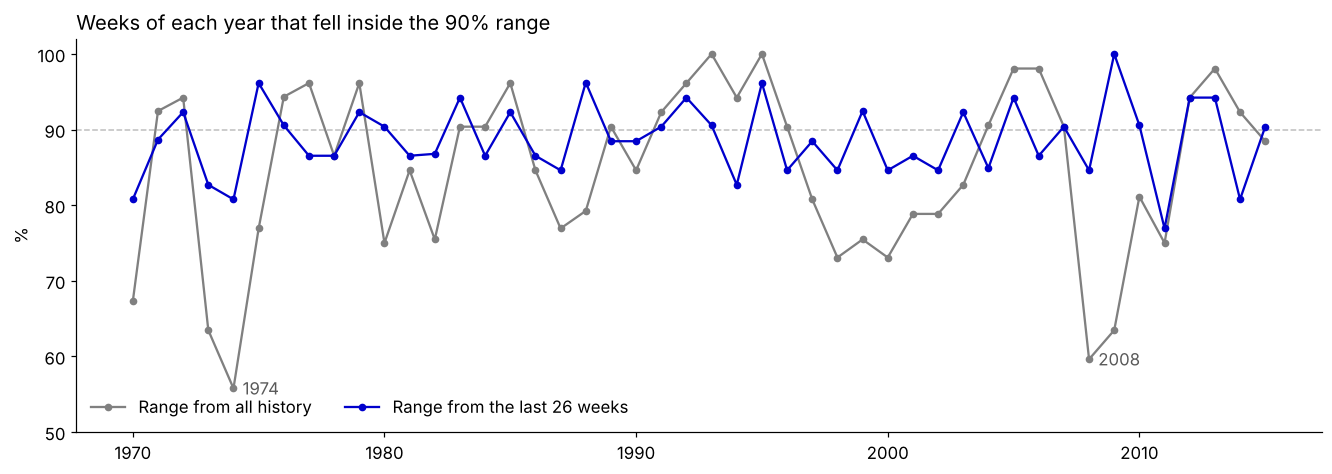

,Worst year,Which,Years under 80%,2008
"Weeks inside the range, %",,,,
Range from all history,56,1974,16,60
Range from the last 26 weeks,77,2011,1,85


Weeks that fell below the low end of the range (it should be 5%):
  Range from all history        7.2% of all weeks, 31% in 1974
  Range from the last 26 weeks  6.3% of all weeks, 13% in 1974


In [6]:
# The last week of the table ends on 1 January 2016 and is left out of the count by year.
by_year = pd.DataFrame({name: 100 * rows.inside.groupby(rows.index.year).mean() for name, rows in ranges.items()}).loc[:2015]
below = pd.DataFrame({name: 100 * rows.below.groupby(rows.index.year).mean() for name, rows in ranges.items()}).loc[:2015]

fig, ax = plt.subplots(figsize=(12, 4.2), layout="constrained")
ax.axhline(90, color="0.75", linewidth=1, linestyle="--")
ax.plot(by_year.index, by_year["Range from all history"], color="0.5", marker="o", markersize=4, label="Range from all history")
ax.plot(by_year.index, by_year["Range from the last 26 weeks"], color="#0000CC", marker="o", markersize=4, label="Range from the last 26 weeks")
for year in (1974, 2008):
    ax.annotate(str(year), (year, by_year.loc[year, "Range from all history"]), xytext=(6, -4), textcoords="offset points", color="0.35")
ax.set(title="Weeks of each year that fell inside the 90% range", ylabel="%", ylim=(50, 102))
ax.legend(loc="lower left", ncols=2)
plt.show()

rows = {name: {"Worst year": round(by_year[name].min()), "Which": by_year[name].idxmin(),
               "Years under 80%": (by_year[name] < 80).sum(), "2008": round(by_year.loc[2008, name])} for name in ranges}
display(pd.DataFrame(rows).T.astype(int).rename_axis("Weeks inside the range, %"))

print("Weeks that fell below the low end of the range (it should be 5%):")
for name, rows_ in ranges.items():
    print(f"  {name:29s} {100 * rows_.below.mean():.1f}% of all weeks, {below[name].max():.0f}% in {below[name].idxmax()}")

h, r = by_year["Range from all history"], by_year["Range from the last 26 weeks"]
assert round(h.min()) == 56 and h.idxmin() == 1974 and round(h[2008]) == 60 and round(r[2008]) == 85
assert (h < 80).sum() == 16 and (r < 80).sum() == 1 and round(r.min()) == 77
assert round(below["Range from all history"].max()) == 31 and round(below["Range from the last 26 weeks"].max()) == 13

The range from all history is right on average and wrong when it counts. In 1974 it held on 56% of weeks, and in 2008 on 60%. In 16 of the 46 years it held less than 80% of the time, and in the worst year almost one week in three fell below the low end that only one week in twenty should reach. A fund holder who took that low end as "about as bad as a week gets" was told so in exactly the years it was least true.

The range from the last 26 weeks widens when the market gets rough and narrows when it calms. It held 85% of the weeks of 2008 and dropped under 80% in a single year.

## Is it the market, or the code?

A difference this large should be checked for a mistake in the forecasters. One way is to take away the thing the second range relies on and see whether its lead goes too. Below, the same 3,443 weekly changes are put in random order: every value is still there, but big weeks no longer come in clusters. If the lead comes from the clusters, it should disappear.

In [7]:
shuffled = changes.copy()
shuffled["change"] = np.random.default_rng(0).permutation(changes["change"].to_numpy())
shuffled_cases = cases_from_series(shuffled, origins=range(first, len(shuffled)), horizon=1, name="shuffled")
control = {"Range from all history": range_results(HistoryRange(), shuffled_cases),
           "Range from the last 26 weeks": range_results(RecentRange(26), shuffled_cases)}

check = summary(control).drop(columns="Average width")
check["Worst year (%)"] = [100 * rows.inside.groupby(rows.index.year).mean().loc[:2015].min() for rows in control.values()]
display(check.round(digits).astype({"Worst year (%)": int}).rename_axis("Weeks in random order"))
assert (check["Weeks inside (%)"].between(88.5, 92)).all() and (check["Worst year (%)"] > 80).all()
assert check["Pinball score"].idxmin() == "Range from all history"

,Weeks inside (%),Pinball score,Worst year (%)
Weeks in random order,,,
Range from all history,91.1,0.231,83
Range from the last 26 weeks,89.8,0.239,85


In random order both ranges hold about 90% of the time and neither has a bad year. The range from all history even scores slightly better, as it should: with nothing to learn from recent weeks, 26 of them are a poorer guide than a few thousand. So the forecasters do what they say, and the lead on the real series comes from the order of the weeks. Calm and rough stretches last, and that is the one thing about next week this notebook found it could forecast.

## What TimeGym added

- Both questions went through the same cases. The forecasters that were asked for a direction and the ones asked for a range saw the same Fridays, with nothing after each Friday in reach.
- A metric of our own, direction right or wrong, was recorded per case beside the built-in ones.
- A range is a checked and scored output. TimeGym verified that every range was in order and recorded coverage, width and the pinball score for each week, so the count by year took one line.
- Kept cases made the paired comparison possible: the interval on the regression's miss says "no difference", and the one on the pinball score says the gain is real.
- The same helper ran on the shuffled series, so the control cost four lines.

## Change one thing

- Follow fewer or more weeks: `RecentRange(13)` or `RecentRange(52)`. Which holds better in 2008, and which over all years?
- Replace the bell-curve multiplier 1.645 with one measured from history, to close the gap between 88.7% and 90%.
- Ask for the next four weeks at once with `horizon=4`. Does the range from the last 26 weeks hold as well in the fourth week?
- Use every trading day: `load("sp500", full=True)` has daily figures, with empty rows where the market was closed. `cases_from_series` will ask you to fill or drop them; the [air quality example](air-quality.ipynb) shows why dropping is the safer choice for the days being scored.

**What this doesn't show.** This is not advice on what to buy or when. The index leaves out dividends and a fund's fees. A range that follows recent weeks still misses the first week of every crash, because nothing before it was large. One-week changes only, from one index. Weeks next to each other are not independent in size, which makes the intervals somewhat too narrow.

**Related:** [Univariate uncertainty](../tutorials/08_univariate_uncertainty.ipynb) explains ranges and their scores, [River flow](river-flow.ipynb) checks a range month by month, and [Bitcoin](bitcoin.ipynb) follows a direction call that looked real. More examples are on the [examples page](../docs/examples.md).